# Seguimiento 4 — EAD y Análisis de Clusters

**Proyecto:** SGRH — Sistema de Gestión de Recursos Humanos · **Base de datos:** AdventureWorks en PostgreSQL (Supabase)

**¿Qué hacemos aquí?**

1. **EAD (Exploración y Análisis de Datos):** revisamos que los datos estén bien y entendemos cómo es la plantilla de la empresa.
2. **Clusters:** agrupamos automáticamente a los empleados en **perfiles parecidos** para descubrir tipos de empleados.

**Tablas usadas:** `employee`, `department`, `shift`, `employeedepartmenthistory` (historial de departamentos), `employeepayhistory` (historial de salarios), `jobcandidate`, `person`, `businessentity`.

## 1. Conexión y carga de datos

Leemos las tablas directamente de la base del proyecto. La conexión sale del archivo `.env` (la misma que usa la app) y **solo se hacen lecturas**: el notebook no modifica nada.

In [1]:
import os, re, warnings
from datetime import date
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from dotenv import load_dotenv
from sqlalchemy import create_engine, text
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

warnings.filterwarnings("ignore")
pd.set_option("display.float_format", "{:,.1f}".format)
PALETA = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4"]
sns.set_theme(style="whitegrid", palette=PALETA)
plt.rcParams.update({"figure.figsize": (10, 4.5), "axes.titleweight": "bold",
                     "axes.spines.top": False, "axes.spines.right": False})
HOY = pd.Timestamp(date.today())

# Conexión: busca el .env en la raíz del proyecto
for carpeta in [Path.cwd(), *Path.cwd().parents]:
    if (carpeta / ".env").exists():
        load_dotenv(carpeta / ".env"); break
url = re.sub(r"^postgres(ql)?://", "postgresql+psycopg://", os.environ["DATABASE_URL"]).split("?")[0]
engine = create_engine(url, connect_args={"connect_timeout": 15})

consultas = {
    "employee": "SELECT * FROM humanresources.employee",
    "department": "SELECT * FROM humanresources.department",
    "shift": "SELECT * FROM humanresources.shift",
    "historial_depto": "SELECT * FROM humanresources.employeedepartmenthistory",
    "historial_salario": "SELECT * FROM humanresources.employeepayhistory",
    "jobcandidate": "SELECT * FROM humanresources.jobcandidate",
    "person": "SELECT businessentityid, firstname, lastname FROM person.person",
    "businessentity": "SELECT * FROM person.businessentity",
}
with engine.connect() as conn:
    conn.execute(text("SET TRANSACTION READ ONLY"))
    t = {nombre: pd.read_sql(sql, conn) for nombre, sql in consultas.items()}

pd.DataFrame({"filas": {k: len(v) for k, v in t.items()}})

,filas
employee,292
department,16
shift,3
historial_depto,300
historial_salario,319
jobcandidate,14
person,19974
businessentity,20779


## 2. ¿Los datos están bien? (calidad)

Antes de analizar, verificamos que la base sea confiable.

In [2]:
emp, dh, ph, cand = t["employee"], t["historial_depto"], t["historial_salario"], t["jobcandidate"]
activos_ids = emp.loc[emp["currentflag"], "businessentityid"]

# Empleados creados desde la app (pruebas): datos originales de AdventureWorks son de 2017 o antes
fecha_alta = pd.to_datetime(t["businessentity"]["modifieddate"], utc=True)
ids_prueba = t["businessentity"].loc[fecha_alta.dt.year >= 2020, "businessentityid"]

pd.Series({
    "Empleados con ID repetido": emp["businessentityid"].duplicated().sum(),
    "Historiales que apuntan a empleados que no existen": (~dh["businessentityid"].isin(emp["businessentityid"])).sum()
        + (~ph["businessentityid"].isin(emp["businessentityid"])).sum(),
    "Empleados activos sin departamento vigente": (~activos_ids.isin(dh.loc[dh["enddate"].isna(), "businessentityid"])).sum(),
    "Empleados activos sin salario": (~activos_ids.isin(ph["businessentityid"])).sum(),
    "Currículums cortados en 2048 caracteres": (cand["resume"].str.len() == 2048).sum(),
    "Empleados de prueba creados desde la app": emp["businessentityid"].isin(ids_prueba).sum(),
}, name="cantidad").to_frame()

,cantidad
Empleados con ID repetido,0
Historiales que apuntan a empleados que no existen,0
Empleados activos sin departamento vigente,0
Empleados activos sin salario,0
Currículums cortados en 2048 caracteres,13
Empleados de prueba creados desde la app,2


**Resultado:** la base está **consistente**: no hay IDs repetidos ni registros "sueltos", y todo empleado activo tiene departamento y salario.

Dos detalles encontrados:
- Los **currículums** de los candidatos quedaron **cortados en 2048 caracteres** durante la migración (un detalle a corregir, no afecta este análisis).
- Hay **2 empleados de prueba** creados desde la app; los **sacamos** del análisis para no mezclar datos de prueba con los reales.

## 3. Una tabla con una fila por empleado

Los salarios y departamentos están en tablas de **historial** (varias filas por persona). Las resumimos para tener **una fila por empleado** con lo que nos interesa: edad, antigüedad, salario actual, departamento y turno actuales.

In [3]:
# Salario actual = el registro más reciente
salario = (ph.sort_values("ratechangedate").groupby("businessentityid").tail(1)
           .set_index("businessentityid")["rate"].astype(float).rename("tarifa_hora"))

# Departamento y turno actuales = la asignación sin fecha de fin
actual = (dh[dh["enddate"].isna()]
          .merge(t["department"][["departmentid", "name"]], on="departmentid")
          .merge(t["shift"][["shiftid", "name"]], on="shiftid", suffixes=("", "_turno"))
          .rename(columns={"name": "departamento", "name_turno": "turno"})
          .set_index("businessentityid")[["departamento", "turno"]])

def anios(desde):
    return ((HOY - pd.to_datetime(desde)).dt.days / 365.25).astype(int)

df = (emp[emp["currentflag"] & ~emp["businessentityid"].isin(ids_prueba)]
      .set_index("businessentityid").join(salario).join(actual))
df["edad"] = anios(df["birthdate"])
df["antiguedad"] = anios(df["hiredate"])
df["nivel"] = df["organizationlevel"].fillna(0)  # el CEO es el nivel 0 (viene vacío en la base)
df["genero"] = df["gender"].map({"M": "Hombre", "F": "Mujer"})
df["tipo_pago"] = np.where(df["salariedflag"], "Asalariado", "Por horas")
df["vacaciones"] = df["vacationhours"]

print(f"Empleados analizados: {len(df)}")
df[["jobtitle", "departamento", "turno", "edad", "antiguedad", "tarifa_hora", "nivel", "vacaciones"]].head()

Empleados analizados: 290


,jobtitle,departamento,turno,edad,antiguedad,tarifa_hora,nivel,vacaciones
businessentityid,,,,,,,,
2,Vice President of Engineering,Engineering,Day,55,18,63.5,1.0,1
3,Engineering Manager,Engineering,Day,51,18,43.3,2.0,2
4,Senior Tool Designer,Tool Design,Day,51,18,29.8,3.0,48
5,Design Engineer,Engineering,Day,74,18,32.7,3.0,5
6,Design Engineer,Engineering,Day,67,18,32.7,3.0,6


## 4. ¿Cómo es la plantilla? (EAD)

### 4.1 Resumen de los números

In [4]:
df[["edad", "antiguedad", "tarifa_hora", "vacaciones", "nivel"]].describe().loc[["mean", "50%", "min", "max"]] \
    .rename(index={"mean": "promedio", "50%": "mediana", "min": "mínimo", "max": "máximo"})

,edad,antiguedad,tarifa_hora,vacaciones,nivel
promedio,47.8,16.7,18.2,50.6,3.5
mediana,47.5,17.0,14.0,51.0,4.0
mínimo,35.0,13.0,9.0,0.0,0.0
máximo,74.0,20.0,125.5,99.0,4.0


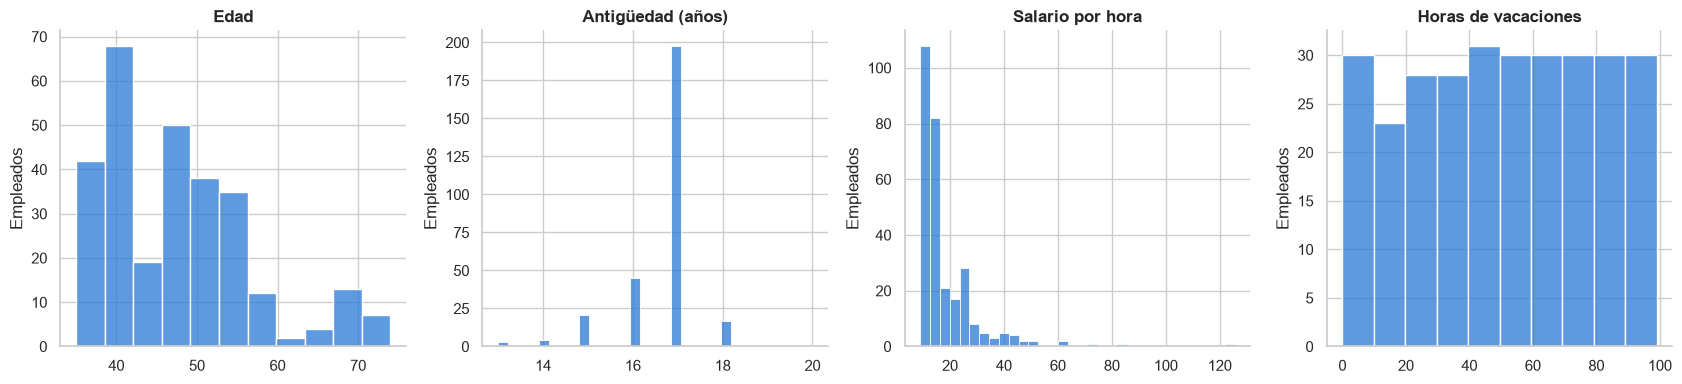

In [5]:
fig, ejes = plt.subplots(1, 4, figsize=(17, 4))
for ax, (col, titulo) in zip(ejes, [("edad", "Edad"), ("antiguedad", "Antigüedad (años)"),
                                    ("tarifa_hora", "Salario por hora"), ("vacaciones", "Horas de vacaciones")]):
    sns.histplot(df[col], ax=ax, color=PALETA[0], edgecolor="white")
    ax.set_title(titulo); ax.set_xlabel(""); ax.set_ylabel("Empleados")
plt.tight_layout(); plt.show()

- **Edad:** entre 35 y 74 años, la mayoría alrededor de los 47.
- **Antigüedad:** casi todos llevan **entre 15 y 19 años**: la empresa contrató a casi todo su personal en 2008–2009.
- **Salario por hora:** la mayoría gana poco (mediana ≈ 14) y unos pocos ganan mucho más (hasta 125): son los **directivos**. No son errores, son datos reales.
- **Vacaciones:** repartidas parejo entre 0 y 99 horas.

### 4.2 ¿Quiénes son?

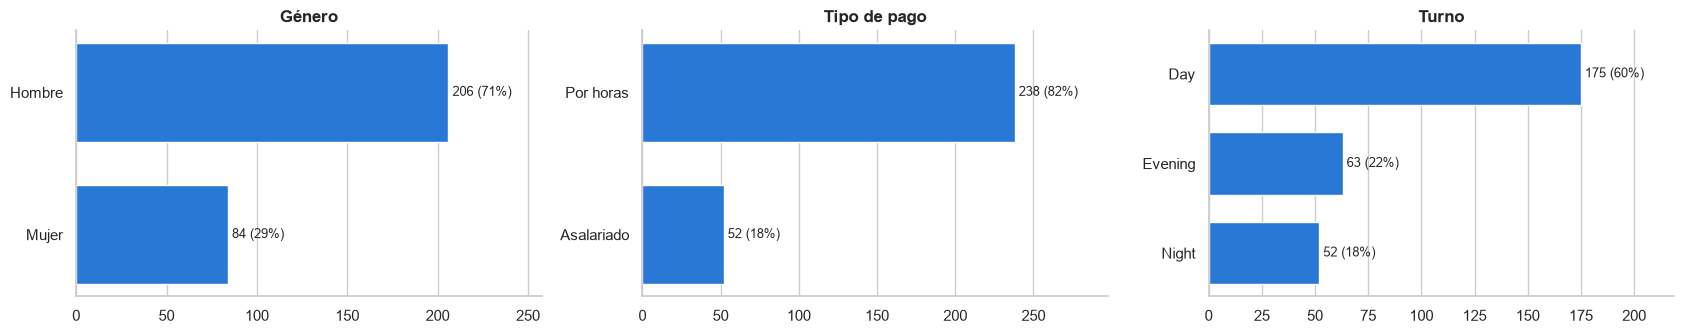

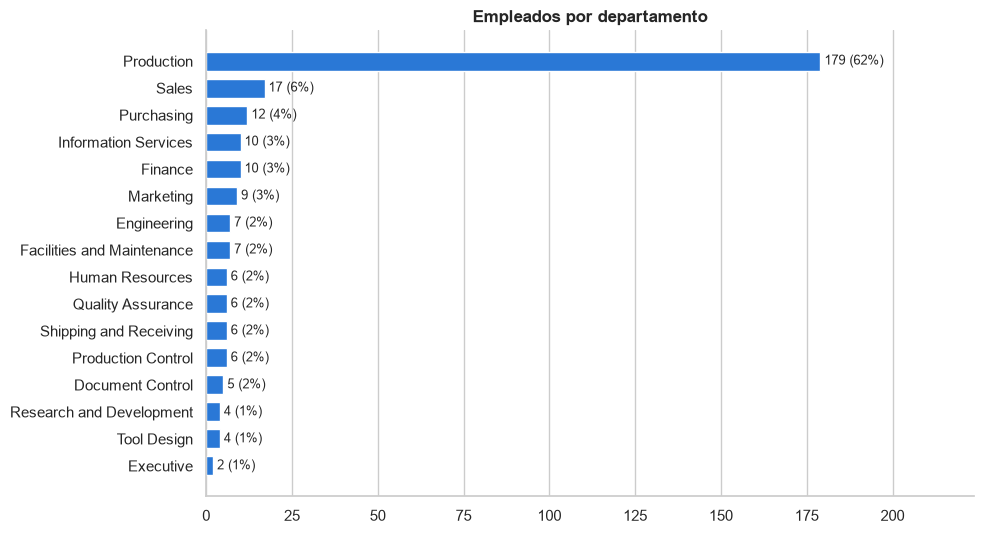

In [6]:
def barras(ax, serie, titulo):
    conteo = serie.value_counts().sort_values()
    ax.barh(conteo.index.astype(str), conteo.values, color=PALETA[0], height=0.7)
    for i, v in enumerate(conteo.values):
        ax.text(v, i, f" {v} ({v / len(serie):.0%})", va="center", fontsize=9)
    ax.set_title(titulo); ax.margins(x=0.25); ax.grid(axis="y", visible=False)

fig, ejes = plt.subplots(1, 3, figsize=(17, 3.5))
barras(ejes[0], df["genero"], "Género")
barras(ejes[1], df["tipo_pago"], "Tipo de pago")
barras(ejes[2], df["turno"], "Turno")
plt.tight_layout(); plt.show()

fig, ax = plt.subplots(figsize=(10, 5.5))
barras(ax, df["departamento"], "Empleados por departamento")
plt.tight_layout(); plt.show()

- Es una empresa **de manufactura**: **Producción tiene el 62 %** del personal.
- **71 % hombres**, **82 % trabaja por horas** (no asalariado).
- El turno de día es el más grande; los turnos de tarde y noche son casi solo de Producción.

### 4.3 ¿De qué depende el salario?

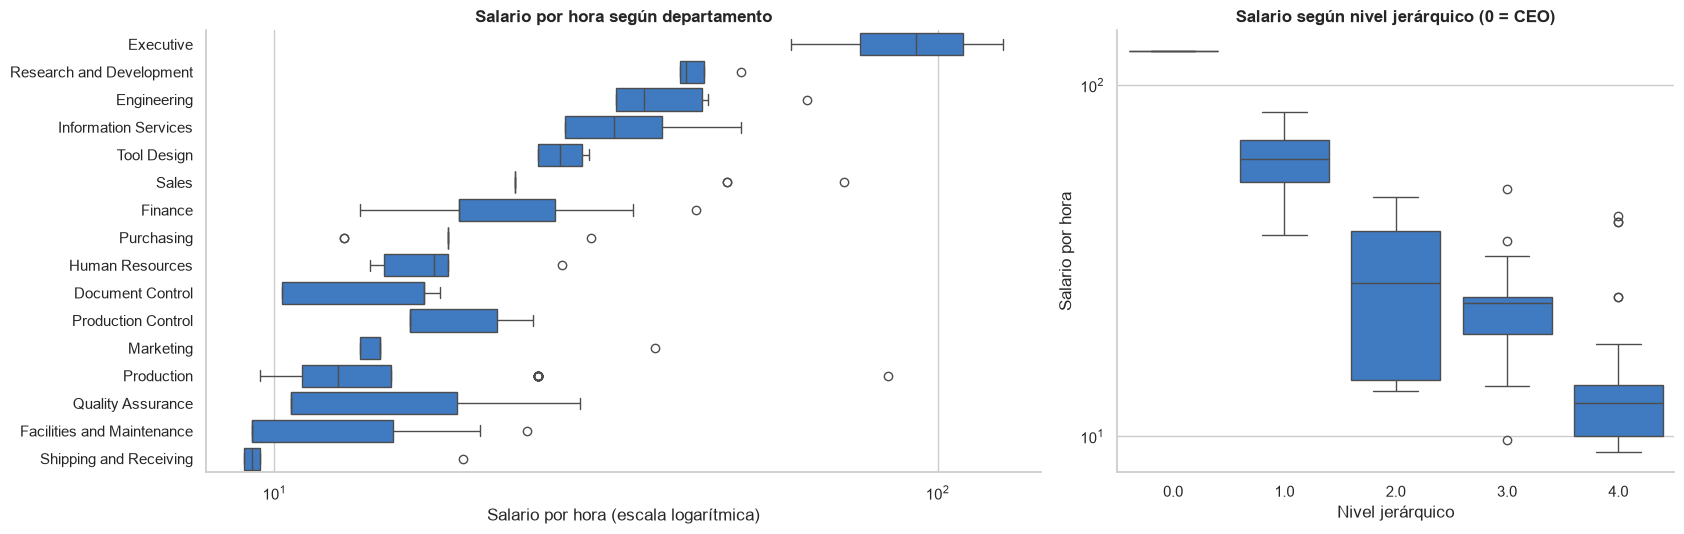

,salario mediano por hora
genero,
Hombre,14.0
Mujer,14.0


In [7]:
orden = df.groupby("departamento")["tarifa_hora"].median().sort_values(ascending=False).index
fig, ejes = plt.subplots(1, 2, figsize=(17, 5.5), gridspec_kw={"width_ratios": [3, 2]})
sns.boxplot(data=df, y="departamento", x="tarifa_hora", order=orden, color=PALETA[0], ax=ejes[0])
ejes[0].set_xscale("log"); ejes[0].set_title("Salario por hora según departamento"); ejes[0].set_ylabel("")
ejes[0].set_xlabel("Salario por hora (escala logarítmica)")
sns.boxplot(data=df, x="nivel", y="tarifa_hora", color=PALETA[0], ax=ejes[1])
ejes[1].set_yscale("log"); ejes[1].set_title("Salario según nivel jerárquico (0 = CEO)")
ejes[1].set_xlabel("Nivel jerárquico"); ejes[1].set_ylabel("Salario por hora")
plt.tight_layout(); plt.show()

df.groupby("genero")["tarifa_hora"].median().rename("salario mediano por hora").to_frame()

- El salario depende sobre todo del **cargo**: a mayor nivel jerárquico, más gana (Ejecutivos, I+D e Ingeniería arriba; Producción y Despacho abajo).
- **Hombres y mujeres** tienen un salario mediano muy parecido: no se ve brecha por género.

### 4.4 ¿Qué variables se parecen entre sí?

La **correlación** va de −1 a 1: cerca de 1 = suben juntas, cerca de −1 = cuando una sube la otra baja, cerca de 0 = no tienen relación.

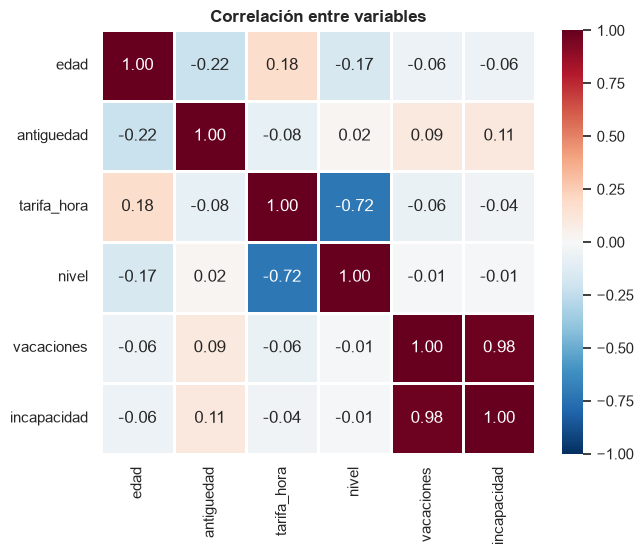

In [8]:
corr = df[["edad", "antiguedad", "tarifa_hora", "nivel", "vacaciones", "sickleavehours"]] \
    .rename(columns={"sickleavehours": "incapacidad"}).corr(method="spearman")
plt.figure(figsize=(7, 5.5))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="RdBu_r", center=0, vmin=-1, vmax=1, linewidths=2)
plt.title("Correlación entre variables"); plt.show()

- **Vacaciones e incapacidad ≈ 0.98:** son prácticamente la misma información (así viene AdventureWorks).
- **Salario y nivel ≈ −0.72:** cuanto más alto en la jerarquía (número más bajo), mejor pagado.
- **Antigüedad** casi no se relaciona con nada, porque todos llevan casi el mismo tiempo.

## 5. Análisis de clusters

### 5.1 ¿Qué es un cluster?

Un **cluster** es un **grupo de elementos que se parecen entre sí**. El análisis de clusters consiste en pedirle a un algoritmo que **agrupe solo** a los empleados, sin decirle de antemano qué grupos existen.

> **Ejemplo:** si tiramos al suelo una bolsa con canicas, botones y monedas, cualquiera las separa en tres montones mirando tamaño, forma y color, sin que nadie le diga los nombres. Eso es hacer clusters: **encontrar los montones naturales**.

Aquí, en vez de canicas, tenemos empleados, y en vez de tamaño y color usamos **4 características**:

| Característica | Por qué |
|---|---|
| **Edad** | Perfil de la persona |
| **Salario por hora** | Cuánto gana |
| **Nivel jerárquico** | Qué tan alto está en la empresa |
| **Horas de vacaciones** | Cuántas vacaciones tiene acumuladas |

(No usamos *antigüedad* porque casi todos tienen la misma, ni *incapacidad* porque repite lo mismo que vacaciones).

### 5.2 ¿Cómo funciona K-Means? (el algoritmo usado)

1. Se elige cuántos grupos queremos (**k**).
2. El algoritmo pone k "centros" y asigna cada empleado al centro **más cercano** (al que más se parece).
3. Mueve cada centro al **promedio** de su grupo y repite hasta que los grupos ya no cambian.

**Detalle importante:** las 4 características tienen escalas distintas (vacaciones va de 0 a 99, nivel de 0 a 4). Para que ninguna pese más solo por tener números grandes, las **estandarizamos** (las ponemos todas en la misma escala).

In [9]:
VARIABLES = ["edad", "tarifa_hora", "nivel", "vacaciones"]
datos = df[VARIABLES].copy()
datos["tarifa_hora"] = np.log(datos["tarifa_hora"])  # el logaritmo evita que los directivos dominen
X = StandardScaler().fit_transform(datos)

### 5.3 ¿Cuántos grupos?

Probamos de 2 a 8 grupos y medimos qué tan bien quedan separados con la **silueta**: va de −1 a 1 y **más alto es mejor** (cada empleado se parece mucho a su grupo y poco a los demás).

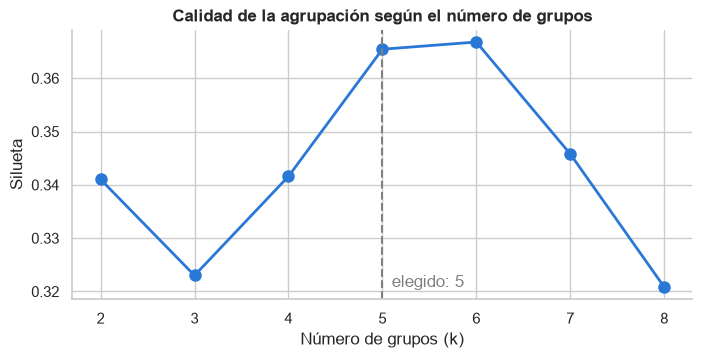

In [10]:
siluetas = {k: silhouette_score(X, KMeans(n_clusters=k, n_init=20, random_state=42).fit_predict(X))
            for k in range(2, 9)}
plt.figure(figsize=(8, 3.5))
plt.plot(list(siluetas), list(siluetas.values()), marker="o", color=PALETA[0], lw=2, ms=8)
plt.axvline(5, color="gray", ls="--"); plt.text(5.1, min(siluetas.values()), "elegido: 5", color="gray")
plt.title("Calidad de la agrupación según el número de grupos"); plt.xlabel("Número de grupos (k)"); plt.ylabel("Silueta")
plt.show()

Las mejores siluetas están en **5 y 6 grupos** (prácticamente empatadas). Elegimos **5** porque es más simple de explicar con el mismo resultado.

### 5.4 Resultado: de grupos numerados a perfiles con nombre

Este resultado se obtiene en **3 pasos**. Es importante separar qué hace el algoritmo y qué hacemos nosotros:

| Paso | Quién lo hace | Qué se obtiene |
|---|---|---|
| 1. Formar los grupos | **El algoritmo** (K-Means) | Un número de grupo (0 a 4) para cada empleado |
| 2. Ponerle nombre a cada grupo | **Nosotros** (analista) | Un nombre que describe a cada grupo según sus promedios |
| 3. Resumir | Código | La tabla final de perfiles |

#### Paso 1 — El algoritmo forma los grupos

K-Means **no entrega nombres**, solo un número de grupo por empleado. Qué empleados quedan juntos lo decide únicamente el algoritmo. Para entender qué tiene en común cada grupo, calculamos sus **promedios**:

In [11]:
K = 5
modelo = KMeans(n_clusters=K, n_init=50, random_state=42).fit(X)
df["grupo"] = modelo.labels_   # <- esto es lo único que entrega el algoritmo: un número por empleado

# Promedios de cada grupo en las 4 características usadas (salida "cruda", todavía sin nombres)
promedios = df.groupby("grupo").agg(
    empleados=("edad", "size"),
    edad=("edad", "mean"),
    salario_hora=("tarifa_hora", "mean"),
    nivel=("nivel", "mean"),
    vacaciones=("vacaciones", "mean"),
)
promedios

,empleados,edad,salario_hora,nivel,vacaciones
grupo,,,,,
0,14,57.6,55.4,1.6,25.1
1,57,40.9,12.2,4.0,81.6
2,93,45.2,12.1,4.0,23.5
3,42,61.3,15.1,3.9,70.1
4,84,47.0,24.3,2.8,54.0


#### Paso 2 — Leemos la tabla y bautizamos cada grupo

Leyendo la tabla de arriba se ve qué distingue a cada grupo:

- Hay **un grupo pequeño con un salario muy por encima del resto** y el nivel jerárquico más alto (número más bajo) → **Dirección y gerencia**.
- Hay **otro grupo con salario intermedio** y nivel medio → **Profesionales y administrativos**.
- Los **otros tres** ganan casi lo mismo (≈ 12–15 por hora) y están en el nivel más bajo (4): son **operarios**. Entre ellos, lo que cambia es la edad y las vacaciones:
  - el de **mayor edad** → **Operarios veteranos**;
  - de los dos que quedan, el de **más vacaciones** → **Operarios jóvenes con muchas vacaciones**;
  - y el de **menos vacaciones** → **Operarios con pocas vacaciones**.

**¿Cómo se asegura el código de poner cada nombre en el grupo correcto?**
El número de cada grupo (0, 1, 2…) **es arbitrario**: no significa nada y puede cambiar si los datos cambian. Por eso **no** escribimos a mano "el grupo 3 es Dirección". En su lugar, el código aplica **las mismas reglas de arriba sobre los promedios**: busca el grupo que cumple cada característica (el de mayor salario, el de mayor edad, etc.) y le asigna el nombre. Así el nombre siempre queda pegado al grupo que realmente tiene esas características.

In [12]:
nombres = {}            # grupo (número) -> nombre
razones = {}            # grupo (número) -> por qué recibió ese nombre
pendientes = promedios.copy()

# Regla 1: el grupo con MAYOR salario promedio es Dirección
g = pendientes["salario_hora"].idxmax()
nombres[g], razones[g] = "Dirección y gerencia", f"mayor salario promedio ({pendientes.loc[g, 'salario_hora']:.1f}/h)"
pendientes = pendientes.drop(g)

# Regla 2: de los que quedan, el de MAYOR salario es Profesionales
g = pendientes["salario_hora"].idxmax()
nombres[g], razones[g] = "Profesionales y administrativos", f"segundo mayor salario ({pendientes.loc[g, 'salario_hora']:.1f}/h)"
pendientes = pendientes.drop(g)

# Los 3 restantes son operarios (salario bajo, nivel 4). Regla 3: el de MAYOR edad son los veteranos
g = pendientes["edad"].idxmax()
nombres[g], razones[g] = "Operarios veteranos", f"operarios de mayor edad ({pendientes.loc[g, 'edad']:.0f} años)"
pendientes = pendientes.drop(g)

# Regla 4: de los 2 operarios que quedan, el de MÁS vacaciones vs. el de MENOS vacaciones
g = pendientes["vacaciones"].idxmax()
nombres[g], razones[g] = "Operarios jóvenes con muchas vacaciones", f"más vacaciones ({pendientes.loc[g, 'vacaciones']:.0f} h) y {pendientes.loc[g, 'edad']:.0f} años"
g = pendientes["vacaciones"].idxmin()
nombres[g], razones[g] = "Operarios con pocas vacaciones", f"menos vacaciones ({pendientes.loc[g, 'vacaciones']:.0f} h)"

df["perfil"] = df["grupo"].map(nombres)

# Tabla de verificación: qué número recibió qué nombre y por qué
pd.DataFrame({"nombre asignado": nombres, "por qué": razones}).sort_index().rename_axis("grupo")

,nombre asignado,por qué
grupo,,
0,Dirección y gerencia,mayor salario promedio (55.4/h)
1,Operarios jóvenes con muchas vacaciones,más vacaciones (82 h) y 41 años
2,Operarios con pocas vacaciones,menos vacaciones (24 h)
3,Operarios veteranos,operarios de mayor edad (61 años)
4,Profesionales y administrativos,segundo mayor salario (24.3/h)


#### Paso 3 — Tabla final de perfiles

Con los nombres ya asignados, resumimos cada perfil. Además de las 4 características usadas, agregamos dos columnas que el algoritmo **no conocía** (`pct_asalariados` y `pct_en_produccion`) para comprobar en el punto 5.5 si los grupos tienen sentido.

In [13]:
# ORDEN solo define en qué orden se muestran las filas y los colores (de menor a mayor salario);
# no cambia a qué grupo pertenece cada empleado.
ORDEN = ["Operarios con pocas vacaciones", "Operarios jóvenes con muchas vacaciones",
         "Operarios veteranos", "Profesionales y administrativos", "Dirección y gerencia"]
resumen = df.groupby("perfil").agg(
    empleados=("edad", "size"),
    edad_promedio=("edad", "mean"),
    salario_hora=("tarifa_hora", "mean"),
    nivel_jerarquico=("nivel", "mean"),
    horas_vacaciones=("vacaciones", "mean"),
    pct_asalariados=("salariedflag", lambda s: s.mean() * 100),
    pct_en_produccion=("departamento", lambda s: (s == "Production").mean() * 100),
).loc[ORDEN]
resumen

,empleados,edad_promedio,salario_hora,nivel_jerarquico,horas_vacaciones,pct_asalariados,pct_en_produccion
perfil,,,,,,,
Operarios con pocas vacaciones,93,45.2,12.1,4.0,23.5,0.0,96.8
Operarios jóvenes con muchas vacaciones,57,40.9,12.2,4.0,81.6,0.0,77.2
Operarios veteranos,42,61.3,15.1,3.9,70.1,0.0,64.3
Profesionales y administrativos,84,47.0,24.3,2.8,54.0,45.2,20.2
Dirección y gerencia,14,57.6,55.4,1.6,25.1,100.0,7.1


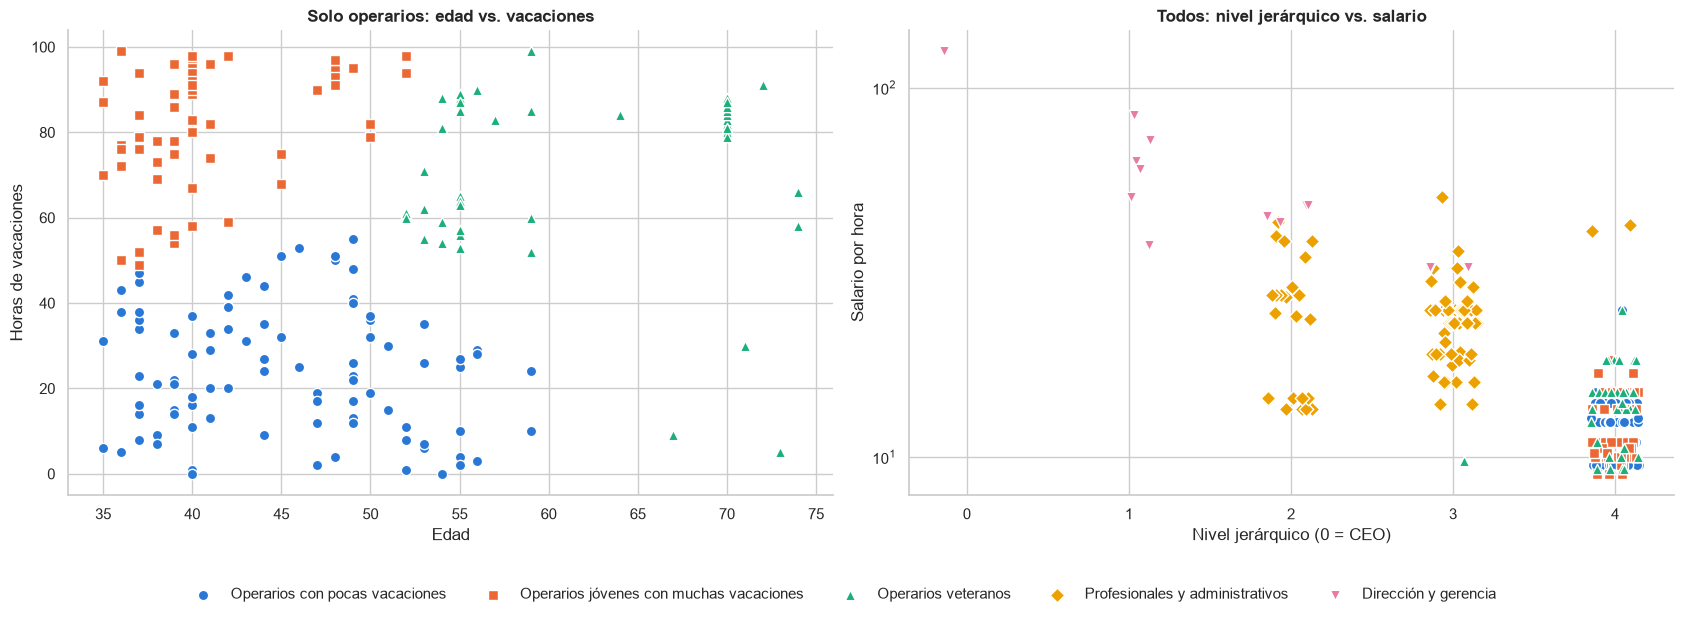

In [14]:
COLOR = dict(zip(ORDEN, PALETA))
MARCA = dict(zip(ORDEN, ["o", "s", "^", "D", "v"]))
fig, ejes = plt.subplots(1, 2, figsize=(17, 6))
for perfil in ORDEN:
    d = df[df["perfil"] == perfil]
    if perfil.startswith("Operarios"):
        ejes[0].scatter(d["edad"], d["vacaciones"], color=COLOR[perfil], marker=MARCA[perfil], s=55, edgecolor="white")
    ejes[1].scatter(d["nivel"] + np.random.default_rng(0).uniform(-0.15, 0.15, len(d)), d["tarifa_hora"],
                    color=COLOR[perfil], marker=MARCA[perfil], s=55, edgecolor="white", label=perfil)
ejes[0].set_title("Solo operarios: edad vs. vacaciones")
ejes[0].set_xlabel("Edad"); ejes[0].set_ylabel("Horas de vacaciones")
ejes[1].set_yscale("log")
ejes[1].set_title("Todos: nivel jerárquico vs. salario")
ejes[1].set_xlabel("Nivel jerárquico (0 = CEO)"); ejes[1].set_ylabel("Salario por hora")
fig.legend(loc="lower center", ncol=5, frameon=False, bbox_to_anchor=(0.5, -0.04))
plt.tight_layout(rect=(0, 0.05, 1, 1)); plt.show()

**Cómo leer los gráficos:** cada punto es un empleado y su color es el grupo que le asignó el algoritmo.
- **Izquierda (solo operarios):** ganan casi lo mismo, pero se separan en tres grupos por **edad** y **vacaciones**: abajo los de pocas vacaciones (azul), arriba a la izquierda los jóvenes con muchas vacaciones (naranja) y a la derecha los veteranos (verde).
- **Derecha:** profesionales y dirección se separan del resto por **salario** y **nivel jerárquico**.

### 5.5 ¿Los grupos tienen sentido?

Una buena prueba: el algoritmo **no conocía** el departamento ni si el empleado es asalariado, pero los grupos que formó coinciden con eso (ver columnas `pct_asalariados` y `pct_en_produccion` de la tabla):

- Los 3 grupos de operarios: **0 % asalariados** y casi todos en **Producción**.
- Profesionales: **45 %** asalariados, pocos en Producción.
- Dirección: **100 %** asalariados.

Es decir, el algoritmo **descubrió solo** la estructura real de la empresa.

## 6. Conclusiones

1. **Los datos son confiables:** la base está consistente; solo se detectaron currículums cortados en la migración y 2 empleados de prueba (excluidos).
2. **La empresa es de manufactura:** 62 % en Producción, 82 % por horas y casi todos contratados en 2008–2009.
3. **El salario depende del cargo** (nivel jerárquico y área), no de la antigüedad ni del género.
4. **Hay 5 perfiles de empleados:** tres tipos de operarios, profesionales/administrativos y dirección.
5. **Hallazgo útil para RR. HH.:** dentro de Producción hay **dos grupos de operarios (≈ 100 personas) con más de 70 horas de vacaciones acumuladas** en promedio. Conviene planificar esas vacaciones por turnos para que no se acumulen más.

**Limitación:** AdventureWorks es una base de ejemplo y la plantilla es pequeña (290 personas), así que los grupos son razonables pero no perfectamente separados.